In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sys
import os

# Get the current working directory
cwd = os.getcwd()

# Get the path to the project's root directory
root_path = os.path.abspath(os.path.join(cwd, os.pardir))

# Add the project's root directory to the Python module search path
sys.path.append(root_path)

Consider a system of linear equations that can be represented in matrix form as $Ax = b$, where $A$ is a matrix of coefficients, $x$ is a vector of variables, and $b$ is a vector of constants.

Our goal is to find the solution to this system of equations that satisfies all equations simultaneously. We achieve this through the Jacobi method, which is an iterative algorithm. This method begins with an initial guess for the solution and updates each variable's value simultaneously based on the last computed values. Convergence requires the spectral radius of the iteration matrix $D^{-1}(L+U)$ to be less than one; strict diagonal dominance of $A$ is a sufficient condition, and without such a condition the method may not converge.

In addition, we want to visually represent this system of equations and its solution in a two-dimensional plane. Each equation is a line in this plane, and the solution of the system is the point where the lines intersect. (This kind of plot is only possible for systems with two unknowns.)

The Python code provided below does exactly this. It plots each equation as a line, uses the Jacobi method to find the solution of the system, and plots the solution as a red point.

Given a diagonally dominant matrix $A = \begin{bmatrix} 3 & 2 \\ \ -1 & 4 \end{bmatrix}$ and a vector $b = \begin{bmatrix} 12 \\ \ 10 \end{bmatrix}$, the Python code will plot the corresponding system of equations and its solution.

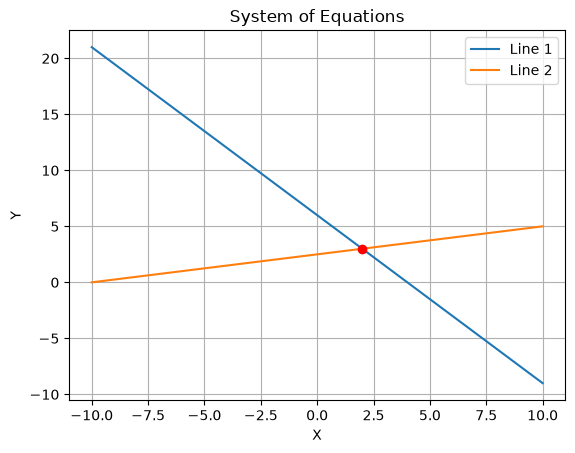

In [2]:
from implementation.jacobi_method import jacobi_method


def plot_system_of_equations(A, b):
    """Plot a system of equations defined by matrix A and vector b."""

    # Generate a range of x values
    x_values = np.linspace(-10, 10, 400)

    # Plot each equation
    for i in range(A.shape[0]):
        # Calculate the corresponding y values
        y_values = (b[i] - A[i, 0] * x_values) / A[i, 1]
        plt.plot(x_values, y_values, label=f"Line {i + 1}")

    # Solve the system of equations for x
    x = jacobi_method(A, b)

    # Plot the solution
    plt.plot(x[0], x[1], "ro")  # solution point

    # Set the labels and title
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title("System of Equations")

    # Show the legend
    plt.legend()

    # Show the plot
    plt.grid()
    plt.show()


A = np.array([[3, 2], [-1, 4]])
b = np.array([12, 10])
plot_system_of_equations(A, b)